In [2]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 43.6 MB/s eta 0:00:00


In [3]:
import spacy
import urllib.request
from gensim.models import Word2Vec
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

In [4]:
print("Scaricamento del testo (Alice in Wonderland)...")
url = "https://www.gutenberg.org/cache/epub/11/pg11.txt"
#Lettura online
testo_grezzo = urllib.request.urlopen(url).read().decode('utf-8')

Scaricamento del testo (Alice in Wonderland)...


In [9]:
print("Caricamento di spaCy e preprocessing")
nlp = spacy.load("en_core_web_sm", exclude=["parser", "ner"])
nlp.add_pipe("sentencizer")
nlp.max_length = len(testo_grezzo) + 1000

Caricamento di spaCy e preprocessing


In [10]:
doc = nlp(testo_grezzo)

processed_sentences = []
# doc.sents divide automaticamente il testo in frasi grazie al sentencizer
for sent in doc.sents:
    clean_sent = []
    for token in sent:
        # Filtriamo stopwords, punteggiatura e teniamo solo parole alfabetiche
        if not token.is_stop and not token.is_punct and token.is_alpha:
            clean_sent.append(str(token.lemma_).lower())

    if len(clean_sent) > 2: # Teniamo solo frasi con almeno un po' di contesto
        processed_sentences.append(clean_sent)

In [11]:
model = Word2Vec(
    sentences=processed_sentences,
    vector_size=100,
    window=5,
    min_count=5,
    sg=1
)

In [12]:
print("\n3. Esplorazione semantica del modello")
target = 'alice'

# - use .most_similar() to explore semantic neighborhoods
if target in model.wv:
    print(f"   Parole più simili a '{target}' (semantic neighborhood):")
    for word, score in model.wv.most_similar(target, topn=5):
        print(f"    - {word} (score: {score:.4f})")


3. Esplorazione semantica del modello
   Parole più simili a 'alice' (semantic neighborhood):
    - head (score: 0.9982)
    - face (score: 0.9982)
    - time (score: 0.9981)
    - away (score: 0.9981)
    - run (score: 0.9981)


   -> Generazione del grafico completata. Apertura in corso


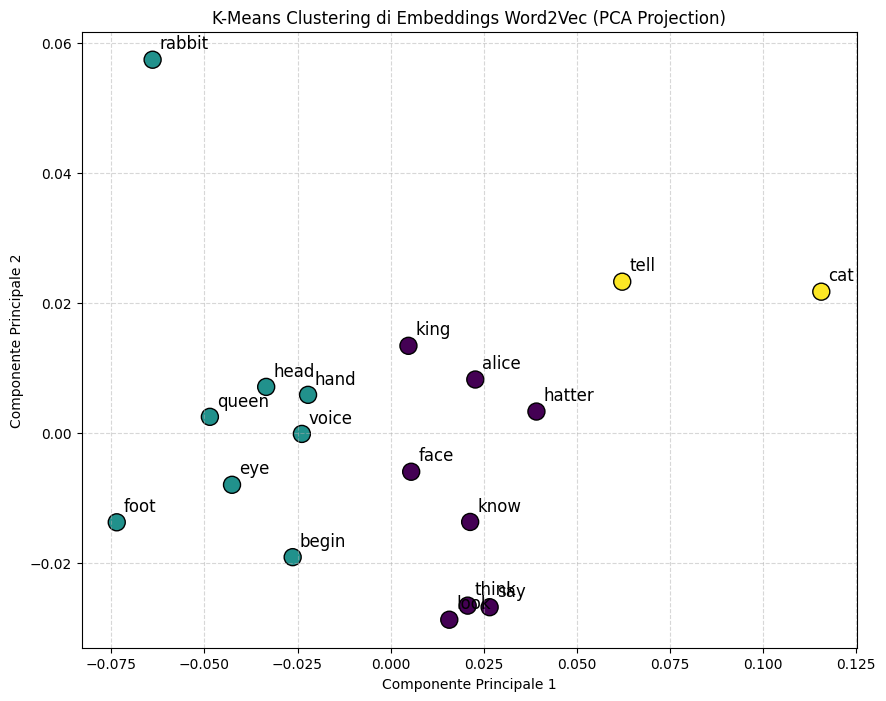

In [13]:
word_list = [
    'alice', 'rabbit', 'queen', 'king', 'cat', 'hatter',  # Personaggi
    'head', 'hand', 'eye', 'foot', 'face', 'voice',       # Parti del corpo
    'say', 'know', 'think', 'look', 'begin', 'tell'       # Verbi
]

valid_words = [w for w in word_list if w in model.wv]
word_vectors = np.array([model.wv[w] for w in valid_words])

#3 cluster secondo le categorie sopra
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(word_vectors)


pca = PCA(n_components=2, random_state=42)
coords_2d = pca.fit_transform(word_vectors)

plt.figure(figsize=(10, 8))

scatter = plt.scatter(coords_2d[:, 0], coords_2d[:, 1], c=cluster_labels, cmap='viridis', s=150, edgecolors='black')

for i, word in enumerate(valid_words):
    plt.annotate(word, xy=(coords_2d[i, 0], coords_2d[i, 1]), xytext=(5, 5),
                 textcoords='offset points', ha='left', va='bottom', fontsize=12)

plt.title('K-Means Clustering di Embeddings Word2Vec (PCA Projection)')
plt.xlabel('Componente Principale 1')
plt.ylabel('Componente Principale 2')
plt.grid(True, linestyle='--', alpha=0.5)

print("   -> Generazione del grafico completata. Apertura in corso")
plt.show()